# **Predicción del Sistema Operativo de un Usuario a Partir de su Comportamiento Digital**

Este dataset registra el comportamiento de usuarios en una plataforma digital, donde cada fila representa una sesión de navegación. El objetivo es predecir qué sistema operativo usa el usuario

### Carga de funciones

In [1]:
#Importamos las librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc
from collections import Counter


In [2]:
# cada vez que se guarde .py, Jupyter lo recargue automáticamente
%load_ext autoreload
%autoreload 2

Diccionario de Variables — Dataset de Comportamiento Digital por Sistema Operativo

| **Variable**       | **Descripción** |
|--------------------|-----------------|
| **duracion**       | Tiempo total (en segundos) que el usuario permaneció realizando la actividad durante la sesión. |
| **paginas**        | Número total de páginas o secciones visitadas por el usuario. |
| **acciones**       | Cantidad de acciones realizadas (clics, formularios, descargas, interacciones, etc.). |
| **valor**          | Valor de la sesión según su relevancia o nivel de conversión. |
| **clase**          | **Variable objetivo** (sistema operativo utilizado):<br>**0 = Windows**, **1 = Macintosh**, **2 = Linux**. |
| **hora_dia**       | Hora del día (0–23) en que ocurre la actividad del usuario. |
| **pais**           | País desde el cual se registró la interacción. |
| **edad**           | Edad del usuario en años. |
| **experiencia**    | Nivel de experiencia tecnológica del usuario (escala sugerida: 1 = baja, 5 = alta). |
| **navegador**      | Navegador web utilizado (Chrome, Firefox, Edge, Safari, etc.). |
| **nivel_usuario**  | Nivel del usuario según su clasificación interna (por ejemplo: básico, intermedio, avanzado). |

---

### Carga de datos

In [4]:
data = pd.read_csv("../data/external/usuarios_win_mac_lin_exp_cmp.csv",encoding='latin1', sep = ';')
data.head()

,duracion,paginas,acciones,valor,clase,hora_dia,pais,edad,experiencia,navegador,nivel_usuario
0,7.0,2,4,8,2,noche,Chile,25.645123,media,Firefox,4.394008
1,21.0,2,6,6,2,tarde,España,55.488254,alta,Chrome,2.887318
2,57.0,2,4,4,2,mañana,Argentina,30.551096,alta,Safari,2.609819
3,101.0,3,6,12,2,noche,USA,37.965528,media,Firefox,2.214545
4,109.0,2,6,12,2,tarde,España,57.256667,alta,Chrome,3.040157


In [5]:
data.columns

Index(['duracion', 'paginas', 'acciones', 'valor', 'clase', 'hora_dia', 'pais',
       'edad', 'experiencia', 'navegador', 'nivel_usuario'],
      dtype='object')

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1230 entries, 0 to 1229
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   duracion       1144 non-null   float64
 1   paginas        1230 non-null   int64  
 2   acciones       1230 non-null   int64  
 3   valor          1230 non-null   int64  
 4   clase          1230 non-null   int64  
 5   hora_dia       1144 non-null   object 
 6   pais           1230 non-null   object 
 7   edad           1230 non-null   float64
 8   experiencia    1230 non-null   object 
 9   navegador      1230 non-null   object 
 10  nivel_usuario  1230 non-null   float64
dtypes: float64(3), int64(4), object(4)
memory usage: 105.8+ KB


In [7]:
data.duplicated().sum() #data.drop_duplicated() esta funcion elimina las filas duplicadas de mi dataset

0

In [ ]:
# Modelos de Clasificación

# 1. Limpieza de tu data
# 2. Analisis Descriptivo
# 3. Organizar tu data a formato numerico (variables cualitativas --> numericas (formato))
# 4. Particion de la data (train y test)
# 5. Balanceo de datos
# 6. Ejecucion de modelos
# 7. Optimizacion de hiperparametros

###  **1. Análisis Descriptivo**

In [8]:
data["clase"].value_counts(normalize = True) * 100 # Diferencia de 66.66666% y 33.333333%

clase
0    50.243902
2    26.341463
1    23.414634
Name: proportion, dtype: float64

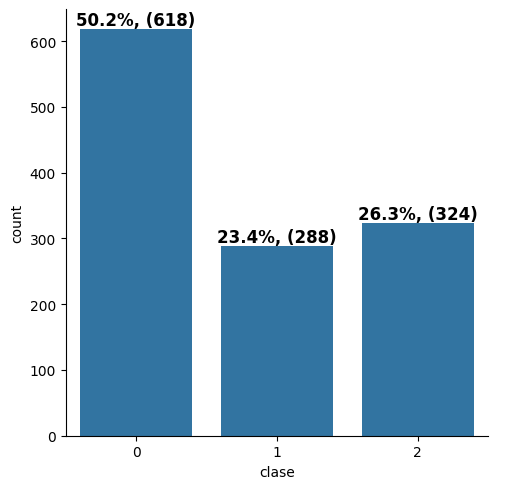

In [9]:
# Crear el gráfico
ax = sns.catplot(x='clase', kind='count', data=data)
total = len(data) # Obtener el total de datos
# Agregar etiquetas con porcentaje y valor absoluto
for p in ax.ax.patches:
    count = int(p.get_height())  # Valor absoluto
    percentage = f"{(count / total) * 100:.1f}%"  # Porcentaje con 1 decimal
    ax.ax.text(p.get_x() + p.get_width() / 2, p.get_height(),
               f"{percentage}, ({count})",
               ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.show()

#### Limpieza de datos

In [10]:
import sys
sys.path.append("../src")

In [11]:
from eda_evaluation import (
    obtener_variables,
    resumen_variables_categoricas,
    mostrar_nulos,
    imputar_valores,
    imputar_valores_extremos
)

In [12]:
# Obtener variables
# Generamos listas de variables numericas y categoricas para un análisis mas ordenado

numeric_vars, categorical_vars = obtener_variables(data)

In [13]:
numeric_vars

['duracion', 'paginas', 'acciones', 'valor', 'clase', 'edad', 'nivel_usuario']

In [14]:
categorical_vars

['hora_dia', 'pais', 'experiencia', 'navegador']

#### Analizando variables numéricas

In [16]:
data[numeric_vars].describe() # describe es una funcion para tener un reporte estadistico basico rapidamente

,duracion,paginas,acciones,valor,clase,edad,nivel_usuario
count,1144.000000,1230.000000,1230.000000,1230.000000,1230.000000,1230.000000,1230.000000
mean,109.382253,2.082114,8.738211,31.621951,0.760976,43.558459,2.991249
std,201.289770,1.527802,9.180839,41.492529,0.842198,15.179240,1.425953
min,1.000000,1.000000,1.000000,1.000000,0.000000,5.019250,-1.271788
25%,11.000000,1.000000,3.000000,7.000000,0.000000,31.000000,2.000000
50%,13.000000,2.000000,6.000000,19.000000,0.000000,43.983275,3.000000
75%,109.250000,2.000000,10.750000,38.000000,2.000000,56.000000,4.000000
max,1117.000000,11.000000,77.000000,398.000000,2.000000,89.157211,6.960731


array([[<Axes: title={'center': 'duracion'}>,
        <Axes: title={'center': 'paginas'}>,
        <Axes: title={'center': 'acciones'}>,
        <Axes: title={'center': 'valor'}>],
       [<Axes: title={'center': 'clase'}>,
        <Axes: title={'center': 'edad'}>,
        <Axes: title={'center': 'nivel_usuario'}>, <Axes: >]],
      dtype=object)

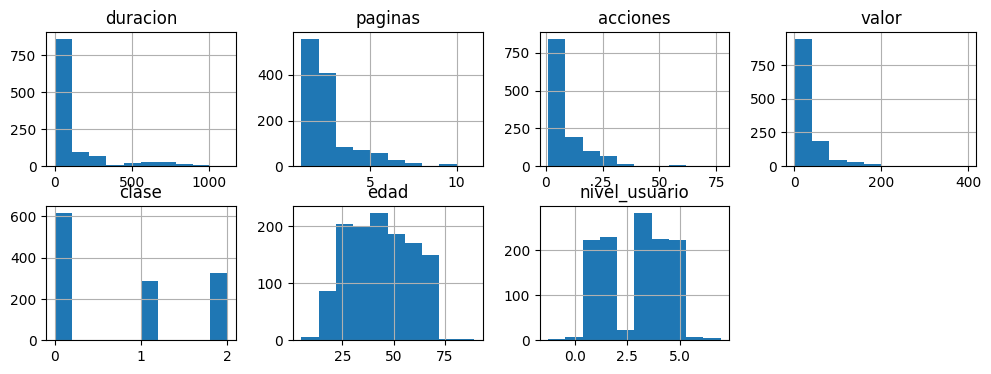

In [20]:
data[numeric_vars].hist(figsize=(12, 4), layout=(2,4), bins=10)

Viendo presencia de valores extremos